# Maqsad: Arabic Sarcasm and Sentiment Analysis

**Executed CPU experiment on the complete official ArSarcasm-v2 split.**

Research question: can joint sarcasm supervision improve sentiment classification? This notebook establishes independent TF-IDF baselines; the separate MARBERT notebook defines the joint-versus-sentiment experiment. Baseline results cannot answer the joint-training hypothesis.

Dataset: Abu Farha, Zaghouani and Magdy (2021), [ArSarcasm-v2](https://aclanthology.org/2021.wanlp-1.36/).

In [1]:
from pathlib import Path
import os, sys, json
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
import matplotlib.pyplot as plt
from maqsad.data import prepare
from maqsad.baseline import train_baseline, predict
from IPython.display import display
print("Python:", sys.version.split()[0])

Python: 3.12.14


## Data integrity and leakage prevention
Download files from an immutable Git revision and verify SHA-256. Preserve the official 3,000-row test set. Remove training rows whose normalized text appears in test, deduplicate the remaining training text, and reserve 15% for validation. Fit TF-IDF on training only. Do not select hyperparameters on test results.

In [2]:
train, validation, test, audit = prepare()
display(pd.Series(audit, name="Rows / setting").to_frame())
assert set(train.text).isdisjoint(validation.text)
assert set(train.text).isdisjoint(test.text)
assert set(validation.text).isdisjoint(test.text)

,Rows / setting
seed,42
original_train,12548
test,3000
train_test_overlap_removed,4
train_duplicates_removed,67
test_duplicate_texts,6
train,10605
validation,1872


## Dataset composition
Dialect groups are imbalanced. Very small groups do not support reliable subgroup conclusions. The label `gulf` covers a broad region and is not a Saudi-only evaluation.

sarcasm,FALSE,TRUE
sentiment,,
NEG,2263,1637
NEU,4715,144
POS,1797,49


,train,validation,test
dialect,,,
egypt,2267,398,306
gulf,534,109,322
levant,520,102,47
magreb,37,6,2
msa,7247,1257,2323


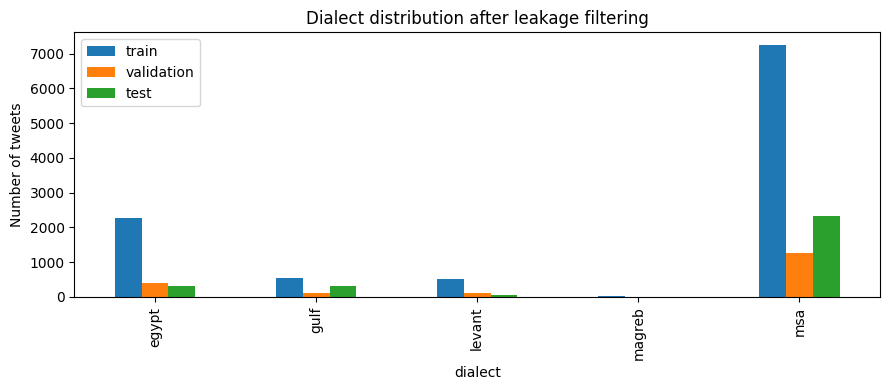

In [3]:
display(pd.crosstab(train.sentiment, train.sarcasm))
counts = pd.DataFrame({"train": train.dialect.value_counts(), "validation": validation.dialect.value_counts(), "test": test.dialect.value_counts()}).fillna(0).astype(int)
display(counts)
ax = counts.plot.bar(figsize=(9, 4), title="Dialect distribution after leakage filtering")
ax.set_ylabel("Number of tweets")
plt.tight_layout()
Path("reports").mkdir(exist_ok=True)
plt.savefig("reports/dialect_distribution.png", dpi=150)
plt.show()

## Train and select the CPU baseline
Character 2–5-gram TF-IDF plus class-balanced logistic regression. Select C from {0.5, 2, 8} on validation: sarcastic-class F1 for sarcasm and macro-F1 for sentiment. Both heads are independent; shared features do not constitute multi-task neural learning. We retain the validation-selected models without refitting on validation.

In [4]:
results = train_baseline()
display(pd.Series(results["validation_selection"], name="Validation F1").to_frame())

,Validation F1
sarcasm_C=0.5,0.531940
sarcasm_C=2.0,0.544980
sarcasm_C=8.0,0.515759
sentiment_C=0.5,0.683140
sentiment_C=2.0,0.685382
sentiment_C=8.0,0.673140


## Held-out test results
Compare against the training-majority classifier. Report sarcastic-class F1 and sentiment macro-F1, not accuracy alone. These are single-seed estimates, not statistical significance claims.

In [5]:
keys = ["sarcasm_f1", "sarcasm_macro_f1", "sentiment_macro_f1", "sentiment_accuracy"]
display(pd.DataFrame({"Majority": {k: results["majority_test"][k] for k in keys}, "TF-IDF": {k: results["test"][k] for k in keys}}))
display(pd.DataFrame(results["test"]["sentiment_report"]).T)
display(pd.DataFrame(results["test"]["by_dialect"]).T)

,Majority,TF-IDF
sarcasm_f1,0.000000,0.540423
sarcasm_macro_f1,0.420738,0.668335
sentiment_macro_f1,0.133049,0.567451
sentiment_accuracy,0.249333,0.636000


,precision,recall,f1-score,support
negative,0.736691,0.767442,0.751752,1677.000
neutral,0.551887,0.312834,0.399317,748.000
positive,0.466828,0.673043,0.551282,575.000
accuracy,0.636000,0.636000,0.636000,0.636
macro avg,0.585135,0.584440,0.567451,3000.000
weighted avg,0.638890,0.636000,0.625455,3000.000


,n,sarcasm_f1,sentiment_macro_f1
egypt,306.0,0.670391,0.358540
gulf,322.0,0.402878,0.502353
levant,47.0,0.457143,0.437328
magreb,2.0,0.000000,0.000000
msa,2323.0,0.522536,0.595540


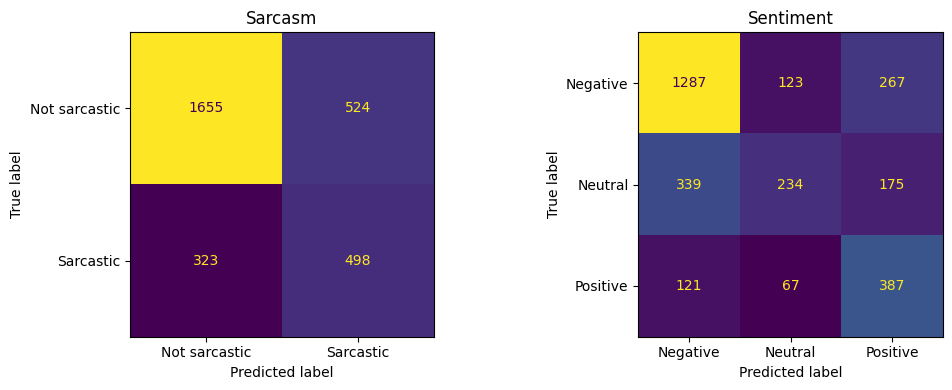

In [6]:
import joblib
from sklearn.metrics import ConfusionMatrixDisplay
bundle = joblib.load("artifacts/baseline.joblib")
x = bundle["vectorizer"].transform(test.text)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(test.sarcasm_label, bundle["sarcasm"].predict(x), labels=[0, 1], display_labels=["Not sarcastic", "Sarcastic"], ax=axes[0], colorbar=False)
ConfusionMatrixDisplay.from_predictions(test.sentiment_label, bundle["sentiment"].predict(x), labels=[0, 1, 2], display_labels=["Negative", "Neutral", "Positive"], ax=axes[1], colorbar=False)
axes[0].set_title("Sarcasm"); axes[1].set_title("Sentiment")
plt.tight_layout()
plt.savefig("reports/confusion_matrices.png", dpi=150)
plt.show()

## Inference on authored examples
These examples are illustrative, not additional labeled evaluation data. Model scores are not calibrated confidence estimates.

In [7]:
examples = ["يا سلام على الخدمة، ساعتين وأنا أنتظر!", "الخدمة ممتازة والتوصيل سريع", "وصل الطلب اليوم"]
display(pd.DataFrame([{"text": t, **r} for t, r in zip(examples, predict(examples))]))

,text,sarcasm,sarcasm_score,sentiment,sentiment_score,model
0,يا سلام على الخدمة، ساعتين وأنا أنتظر!,False,0.257520,negative,0.391418,tfidf_independent_heads
1,الخدمة ممتازة والتوصيل سريع,False,0.270005,positive,0.432901,tfidf_independent_heads
2,وصل الطلب اليوم,False,0.102361,neutral,0.598176,tfidf_independent_heads


## Limitations and next experiment
The dataset is composed of historical tweets and may not generalize to present-day customer reviews. Sarcasm can require conversational context. Minority dialect metrics can be unstable (the official Maghrebi test group has only two examples).

Run `02_marbert_finetuning.ipynb` on a GPU with model-download access. Compare joint learning with sentiment-only fine-tuning using the same split, encoder revision, seed, sequence length and training budget. Repeat with at least three seeds before making a robust improvement claim. No MARBERT result is claimed by this notebook.